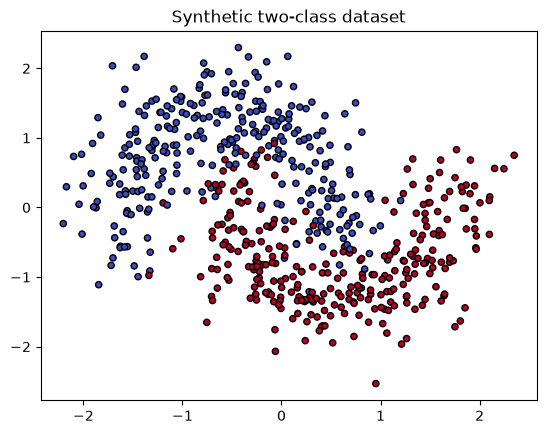

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

X, y = make_moons(n_samples=1000, noise=0.25, random_state=42)
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42, stratify=y_tmp)

sc = StandardScaler().fit(X_train)
X_train, X_val, X_test = sc.transform(X_train), sc.transform(X_val), sc.transform(X_test)

plt.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='coolwarm', edgecolor='k', s=20)
plt.title("Synthetic two-class dataset")
plt.show()

In [2]:
linear = LogisticRegression().fit(X_train, y_train)
lin_train = accuracy_score(y_train, linear.predict(X_train))
lin_val = accuracy_score(y_val, linear.predict(X_val))
print(f"Linear model -> train: {lin_train:.3f} | validation: {lin_val:.3f}")

Linear model -> train: 0.862 | validation: 0.845


In [3]:
rows = []
for h in [2, 4, 8, 16, 32]:
    for lr in [0.001, 0.01, 0.1]:
        nn = MLPClassifier(hidden_layer_sizes=(h,), activation='relu',
                           learning_rate_init=lr, max_iter=1000, random_state=42).fit(X_train, y_train)
        rows.append({"Model": "Neural Net (ReLU)", "Hidden units": h, "Learning rate": lr,
                     "Train acc": accuracy_score(y_train, nn.predict(X_train)),
                     "Val acc": accuracy_score(y_val, nn.predict(X_val))})

rows.append({"Model": "Linear (Logistic Reg.)", "Hidden units": "-", "Learning rate": "-",
             "Train acc": lin_train, "Val acc": lin_val})

results = pd.DataFrame(rows).sort_values("Val acc", ascending=False).reset_index(drop=True)
results

c:\Users\anupa\OneDrive\Desktop\week 2 Deep Learning\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Hidden units,Learning rate,Train acc,Val acc
0,Neural Net (ReLU),32,0.1,0.941667,0.965
1,Neural Net (ReLU),16,0.01,0.943333,0.950
2,Neural Net (ReLU),16,0.1,0.940000,0.950
3,Neural Net (ReLU),32,0.01,0.945000,0.950
4,Neural Net (ReLU),8,0.01,0.935000,0.945
5,Neural Net (ReLU),32,0.001,0.945000,0.940
6,Neural Net (ReLU),16,0.001,0.941667,0.935
7,Neural Net (ReLU),8,0.1,0.933333,0.935
8,Neural Net (ReLU),8,0.001,0.915000,0.925
9,Neural Net (ReLU),4,0.001,0.858333,0.850


In [4]:
best = results[results["Model"] == "Neural Net (ReLU)"].iloc[0]
h, lr = int(best["Hidden units"]), float(best["Learning rate"])
print("Best settings -> hidden units:", h, "| learning rate:", lr)

best_nn = MLPClassifier(hidden_layer_sizes=(h,), activation='relu', learning_rate_init=lr,
                        max_iter=1000, random_state=42).fit(X_train, y_train)

final = []
for name, m in [("Linear", linear), ("Neural Net", best_nn)]:
    p = m.predict(X_test)
    final.append({"Model": name, "Test accuracy": accuracy_score(y_test, p),
                  "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p)})
pd.DataFrame(final)

Best settings -> hidden units: 32 | learning rate: 0.1


,Model,Test accuracy,Precision,Recall
0,Linear,0.87,0.87,0.87
1,Neural Net,0.93,0.93,0.93


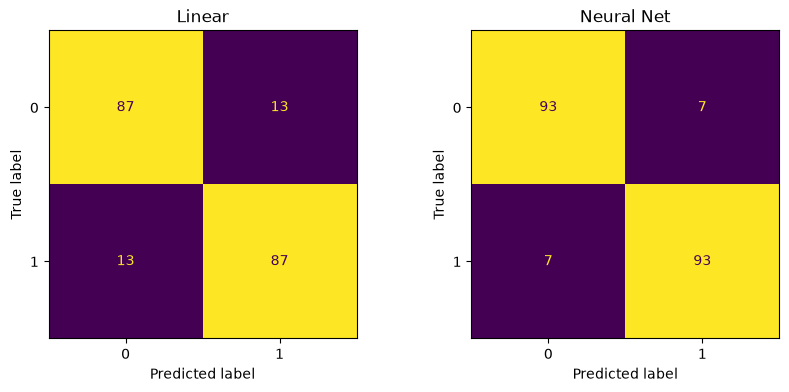

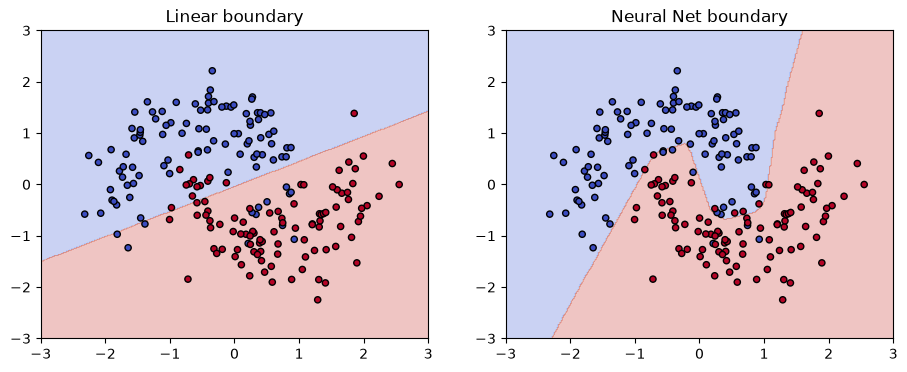

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, m) in zip(ax, [("Linear", linear), ("Neural Net", best_nn)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test))).plot(ax=a, colorbar=False)
    a.set_title(name)
plt.show()

xx, yy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (name, m) in zip(ax, [("Linear", linear), ("Neural Net", best_nn)]):
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    a.scatter(X_test[:,0], X_test[:,1], c=y_test, cmap='coolwarm', edgecolor='k', s=20)
    a.set_title(name + " boundary")
plt.show()

In [ ]:
## Conclusion

I compared a linear model (logistic regression) with a neural network that has one hidden layer and ReLU activation, on a two-class dataset with a curved pattern (make_moons, 1000 samples, 60/20/20 train/validation/test split).

**Results (validation accuracy)**
| Model | Hidden units | Learning rate | Train acc | Val acc |
|---|---|---|---|---|
| Linear (Logistic Reg.) | - | - | 0.862 | 0.845 |
| Neural Net (ReLU) | 2 | 0.01 | 0.852 | 0.830 |
| Neural Net (ReLU) | 4 | 0.01 | 0.862 | 0.850 |
| Neural Net (ReLU) | 8 | 0.01 | 0.935 | 0.945 |
| Neural Net (ReLU) | 16 | 0.01 | 0.943 | 0.950 |
| Neural Net (ReLU) | 32 | 0.1 (best) | 0.942 | 0.965 |

Test accuracy: linear = 0.87, best neural network (32 units, learning rate 0.1) = 0.93.

**Which model performed best and why**
The neural network with 32 hidden units and a learning rate of 0.1 performed best, with the highest validation accuracy (0.965). The data is curved, and a linear model can only draw one straight line, so it underfits (about 0.85 on both training and validation). The neural network uses a nonlinear activation (ReLU), so it can bend its boundary to follow the curve.

**Effect of hidden-layer size**
With 2 or 4 hidden units the network was no better than the linear model (0.83 to 0.85), because it did not have enough units to capture the curve. From 8 units upward, validation accuracy jumped to 0.925 to 0.965.

**Effect of learning rate**
The smallest learning rate (0.001) learned more slowly and was usually a little worse. For example, with 8 units it scored 0.925 against 0.945 at 0.01. For the larger networks, 0.01 and 0.1 gave the best results.

**Overfitting check**
Training and validation accuracy were close for all the larger networks (for the best model, 0.942 train against 0.965 validation), so the model learned the real pattern and did not memorise the training data.

**Final choice**
The settings were chosen using validation data only, and the test data was used once at the end. The neural network is the better model.